## Huddle Clip to Interaction Features

This notebook follows a single huddle through our computer vision pipeline. The huddle has already been segmented by gemini and it is in a small-clipped form. We will look at the Hope vs Calvin set 1 huddle 8 clip.

After we show the computer vision pipeline, we will reproduce the full figures at the end of this demo.

Instructions:
1) Select the project's Python environment as the kernel, then start the kernel.
2) Run the cells in the order they follow below, from top to bottom (or choose Run All).


In [2]:
from IPython.display import Video
import pandas as pd

### 1) Computer Vision
The first part of this demo will go over the computer vision modeling on the raw huddle footage. First, we will look at just the huddle clip on its own. 

In [3]:
Video("demo/clip.mp4", width=640)


#### Line Detection

The first part of our model was to detect the court lines which would allow us to build the necessary homography combat the distorted camera angle. These lines were detected with our fine-tuned SAM3 model and the prompt "white court lines."

In [4]:
Video("demo/court_lines.mp4", width=640)

#### Player Detection

After we detect the court lines we can detect the player locations on either side. These players were detected and tracked with SAM3 prompted with "female volleyball player playing."

In [5]:
Video("demo/players_masks.mp4", width=640)


#### Player Mapping

Now, putting the court lines and player tracking together we are able to obtain a clear mapping to a true court. On the right we can see the bird eye view version of the players and on the bottom are the graphs for the spread of the players. 

In [6]:
Video("demo/gyration_graph_bev.mp4", width=640)

#### Frame-by-Frame Data

The video above is the stage that obtains a frame-by-frame data set of each huddle which can be seen below. 

In [7]:
# head of the frame by frame data of hope vs calvin set 1 huddle 8
frames = pd.read_csv("data/Calvin_vs_Hope/all_sets.csv")
frames = frames[(frames["set"] == 1) & (frames["huddle_number"] == 8)]

cols = ["set", "huddle_number", "frame", "time_s", "left_n", "left_cx", "left_cy",
        "left_r_gyration", "left_hull_area", "right_n", "right_r_gyration", "right_hull_area"]
frames[cols].head()


,set,huddle_number,frame,time_s,left_n,left_cx,left_cy,left_r_gyration,left_hull_area,right_n,right_r_gyration,right_hull_area
4723,1,8,0,0.000,6,6.566500,5.083333,2.315081,12.035553,6,3.204098,19.357653
4724,1,8,1,0.033,6,6.494667,5.064500,2.326979,12.129184,6,3.176855,18.755978
4725,1,8,2,0.067,6,6.414833,5.087000,2.322777,12.256329,6,3.135809,18.122985
4726,1,8,3,0.100,6,6.356500,5.094167,2.326689,12.339744,6,3.096698,17.607060
4727,1,8,4,0.133,6,6.614000,5.149000,2.297682,12.096790,6,3.088412,17.371285


#### Features

##### Closeness

We will now get into the three features: closeness, duration, and latency. First, closeness, which is measured as the minimum spread diameter over the entire clip. This can be seen in the graph at the lowest point. As the video shows, the team on the right huddled closer together than the team on the left (2.95ft vs 4.02ft).

In [8]:
Video("demo/spread_closeness.mp4", width=640)

##### Duration

Now, looking at duration, this can be measured as how long the team stays close together in their huddle before dispersing. On the graph, it is denoted with a different colored background. As seen in the video, the team on the left huddled longer than the team on the right (1.83s vs 1.53s).

In [9]:
Video("demo/spread_duration.mp4", width=640)

##### Latency

Lastly, we can look at the latency of the huddle, which is how long it took the players to come together to form the huddle. On the graph it is depicted with a line under the x-axis and a color change on the line in the chart. As seen in the video, both teams come together in roughly the same amount of time.

In [10]:
Video("demo/spread_latency.mp4", width=640)

#### Huddle Dataset

We now have a more compact dataset of each feature. This clean data set can be seen below. Here closeness is `circle_diameter_gyranchor_ft`, duration is `duration_circle_s`, and latency is `latency_size_adj_s`.
Note that latency is adjusted for starting position: teams that start farther apart naturally take longer to come together, so we remove starting spread as a confounding variable. 
The adjusted latency (`latency_size_adj_s`) is therefore positive or negative relative to how fast or slow a team should be expected to come together, with positive meaning faster than expected.

In [11]:
# single row for calvin and hope each of huddle 8 set 1
long = pd.read_csv("data/long_dataset.csv")
huddle = long[(long["game_id"] == "Calvin_vs_Hope") & (long["set"] == 1) & (long["huddle_number"] == 8)].copy()
huddle["won_before"] = 1 - huddle["lost_before"]

cols = ["game_id", "set", "huddle_number", "team", "opponent", "won_before", "won_after",
        "circle_diameter_gyranchor_ft", "duration_circle_s", "latency_size_adj_s"]
huddle[cols]


,game_id,set,huddle_number,team,opponent,won_before,won_after,circle_diameter_gyranchor_ft,duration_circle_s,latency_size_adj_s
1313,Calvin_vs_Hope,1,8,Hope,Calvin,1.0,1.0,4.018203,1.833333,-0.961414
1509,Calvin_vs_Hope,1,8,Calvin,Hope,0.0,0.0,2.945926,1.533333,0.447022


#### Full Dataset

Now, this gets applied to all of the huddles in our dataset. Once we have the whole dataset we can run our analysis to obtain the figures from our paper. 

In [12]:
# head of total dataset
cols = ["game_id", "set", "huddle_number", "team", "opponent", "lost_before","won_after",
        "circle_diameter_gyranchor_ft", "duration_circle_s", "latency_size_adj_s"]

df = pd.read_csv("data/long_dataset.csv")
df.head(10)[cols]

,game_id,set,huddle_number,team,opponent,lost_before,won_after,circle_diameter_gyranchor_ft,duration_circle_s,latency_size_adj_s
0,Adrian_vs_Oberlin,1,1,ADRIAN,Ober,0.0,1.0,3.126702,0.633333,0.541328
1,Adrian_vs_Oberlin,1,2,ADRIAN,Ober,0.0,0.0,3.077136,1.700000,-0.396089
2,Adrian_vs_Oberlin,1,3,ADRIAN,Ober,1.0,1.0,4.302265,0.933333,-0.100038
3,Adrian_vs_Oberlin,1,4,ADRIAN,Ober,0.0,1.0,3.479856,0.266667,0.252179
4,Adrian_vs_Oberlin,1,5,ADRIAN,Ober,0.0,0.0,4.946581,0.133333,0.599854
5,Adrian_vs_Oberlin,1,6,ADRIAN,Ober,1.0,1.0,5.021938,0.233333,-2.370581
6,Adrian_vs_Oberlin,1,7,ADRIAN,Ober,0.0,0.0,3.999414,0.900000,-0.035773
7,Adrian_vs_Oberlin,1,8,ADRIAN,Ober,1.0,0.0,2.706585,1.166667,0.070099
8,Adrian_vs_Oberlin,1,9,ADRIAN,Ober,1.0,1.0,2.579512,1.466667,0.026662
9,Adrian_vs_Oberlin,1,10,ADRIAN,Ober,0.0,0.0,3.515619,0.633333,-1.198115


In [13]:
# run the team- and game-level analysis on the full dataset (prints the numbers the figures are built from)
import sys
sys.path.insert(0, "analysis/statistical_analysis")
import importlib
import huddle_feature_analysis as h
importlib.reload(h)  # pick up any edits to the script without restarting the kernel

long_df = h.prep(h.clean_long_df(pd.read_csv(h.LONG_DATASET_CSV_PATH), verbose=False))
h.consistency_section(long_df)


[unfiltered] team-huddle rows: 10362  |  huddles: 5359  |  sets: 128
=== Recovery-routine consistency (cold-streak LOMO-AUC) ===
(cold streak = 2+ points lost in a row; comparison = momentum >= 0 or a single loss followed by a won point)
Team level (n=48 teams): consistency vs point-win %  Pearson r=+0.361 (p=0.012)  Spearman rho=+0.287 (p=0.048)
Game level: higher-consistency team won 23 of 32 games (72%), exact sign test p=0.020
  mean winner-minus-loser consistency = +0.062  (paired t p=0.010, Wilcoxon p=0.008)
  winning margin (points): higher-consistency winners 13.4 (n=23) vs lower-consistency winners 9.8 (n=9)
  Won game: mean consistency 0.737 (n=32)
  Lost game: mean consistency 0.675 (n=32)
Losing streaks (2+ lost in a row): mean length high-consistency 2.82 vs low 2.79 (Welch p=0.755); streaks per team 29.5 vs 27.1
Early vs late sets: mean consistency 0.705 vs 0.706 (n=61 team-games, paired t p=0.978)



scatter: n=48 r=+0.361 p=0.012


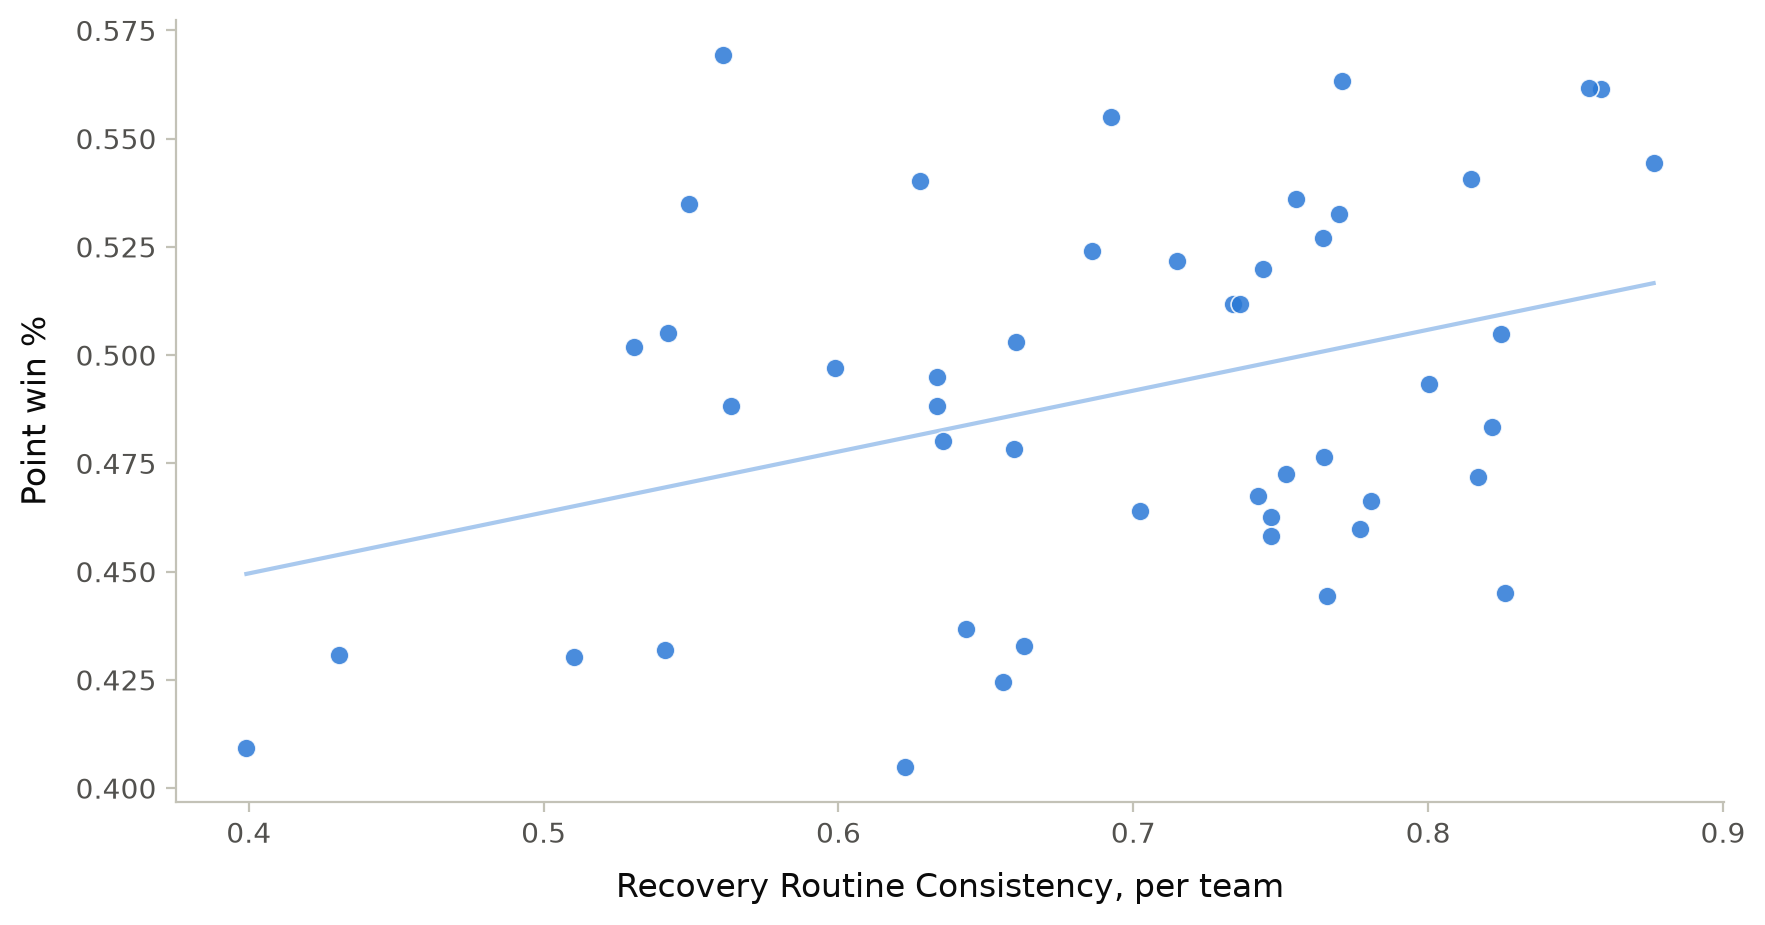

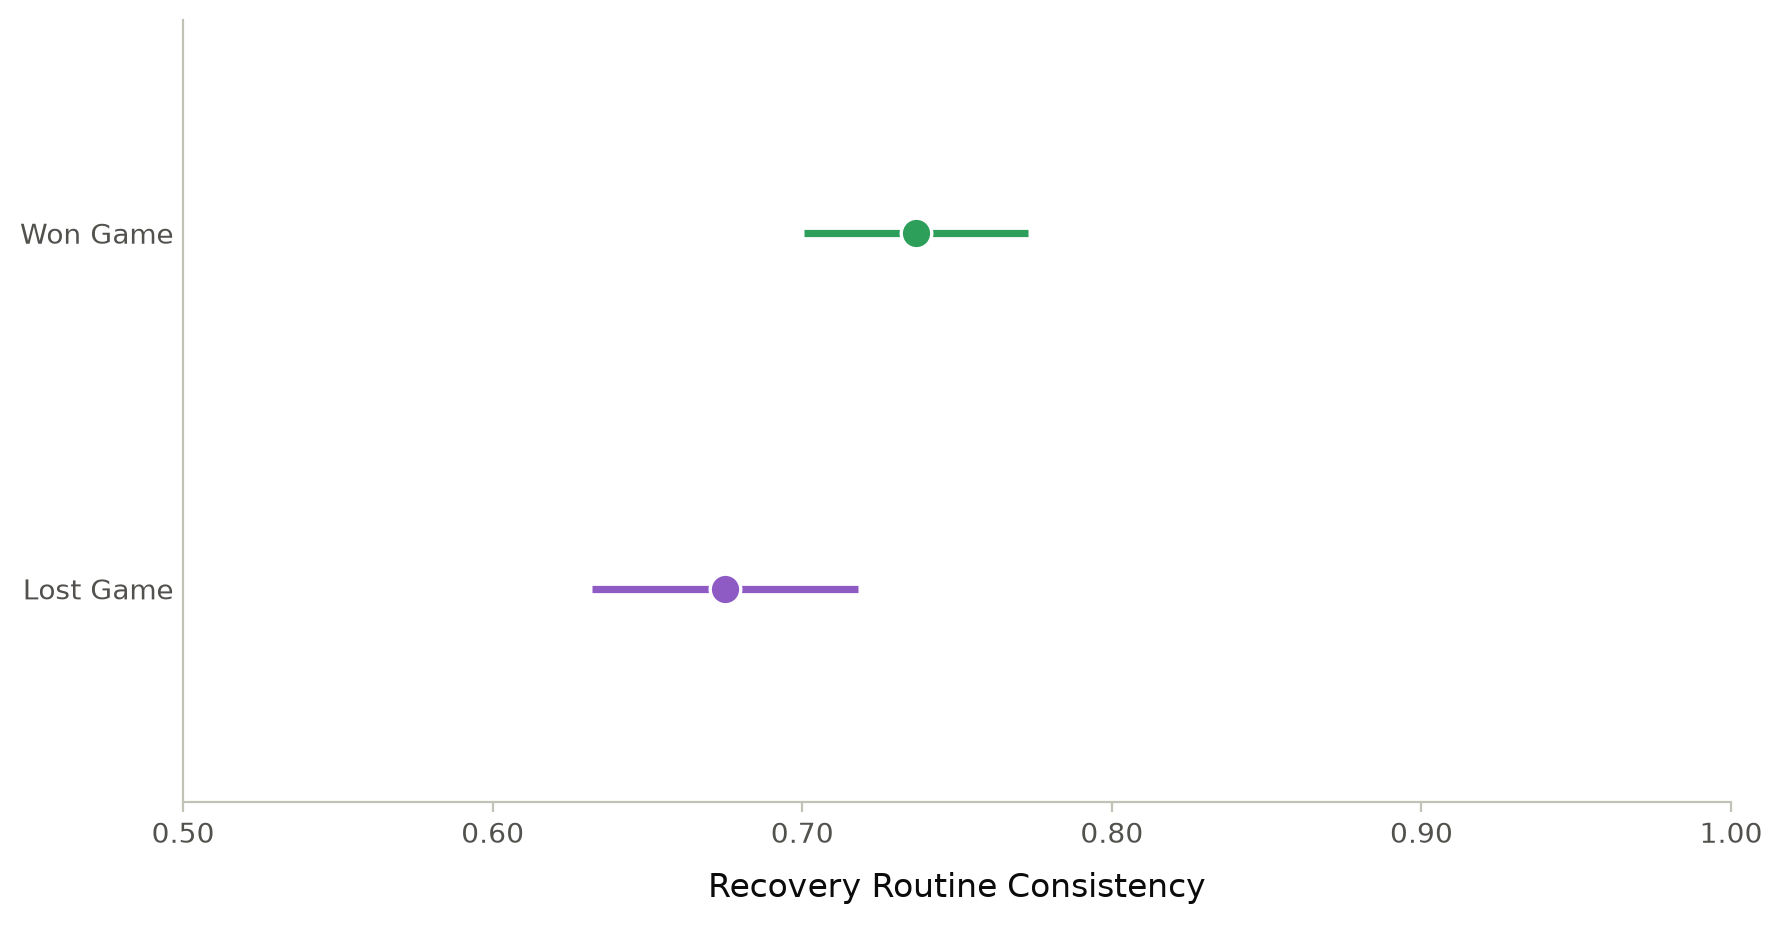

[unfiltered] team-huddle rows: 10362  |  huddles: 5359  |  sets: 128


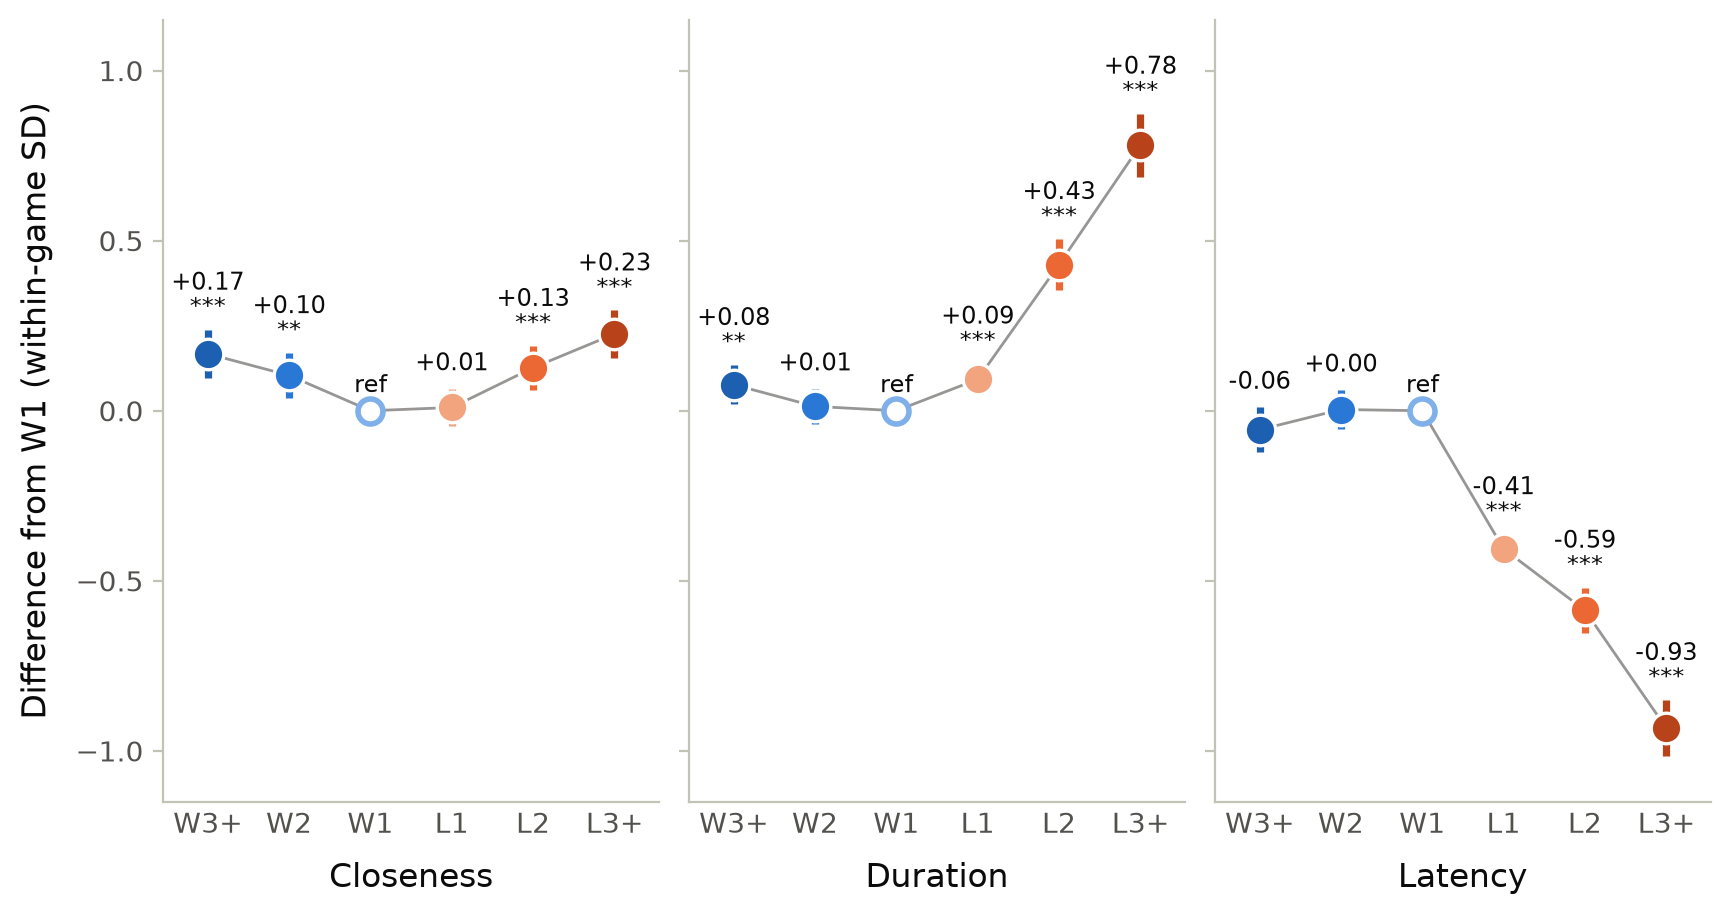

In [14]:
# draw the three paper figures (shown here, not saved to disk)
import os
os.environ["PAPER_FIGURES_SHOW"] = "1"
%run analysis/statistical_analysis/paper_figures.py
